# Human atlas: lineage annotation (stage 04)

Every cluster of the whole-tissue scVI clustering is assigned one lineage (or EXCLUDE); the lineage objects re-integrated in 04b are cut from these labels.

Clustering: `data/interim/latent_human.h5ad`, column `leiden_scVI_2.5`. Decisions: `resources/annotations/human_lineage.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "lineage", "leiden_scVI_2.5"
OBJECT = REPO / "data/interim/latent_human.h5ad"
TABLE = REPO / "resources/annotations/human_lineage.csv"
PANEL = ['EPCAM', 'KLF5', 'COL5A1', 'COL6A3', 'DCN', 'LEFTY2', 'IGFBP1', 'ACTA2', 'MYH11', 'PTPRC', 'STK17B', 'PECAM1', 'VWF', 'PDGFRA', 'PRL', 'CDH1', 'PAX8', 'FLT1', 'RGS5', 'TAGLN']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,epithelial,1201,leiden_scVI_2.5,"CDH1 0.41; PAX8 0.60; EPCAM 0.28 | top vs level: RHEX 1.00, CADM1 0.96, EYA2 0.97"
1,perivascular,996,leiden_scVI_2.5,"PECAM1 0.80; FLT1 0.70; RGS5 0.05 | top vs level: PLCB4 0.84, LIFR 0.83, PTPRB 0.78"
2,epithelial,4093,leiden_scVI_2.5,"CDH1 0.38; PAX8 0.60; EPCAM 0.23 | top vs level: EYA2 0.98, NPAS3 0.98, MECOM 0.99"
3,EXCLUDE,1137,leiden_scVI_2.5,"EXCLUDE: doublet score med 12.40 (level q75 0.26), genes med 2168 (level q25 1265), 0.72 co-express 2+ lineage panels (level 0.39); panels: endometrial_fibroblasts 0.73, immune 0.68, smooth_muscle..."
4,perivascular,817,leiden_scVI_2.5,"PECAM1 0.74; FLT1 0.05; RGS5 0.02 | top vs level: MMRN1 0.91, TFPI 0.96, SMAD1 0.94"
5,immune,870,leiden_scVI_2.5,"PTPRC 0.79 | top vs level: TBXAS1 0.86, FMN1 0.86, PLXDC2 0.94"
6,stromal,3677,leiden_scVI_2.5,"PDGFRA 0.82; DCN 0.79; PRL 0.05 | top vs level: NEAT1 0.99, MMP10 0.80, SOX4 0.93"
7,stromal,2475,leiden_scVI_2.5,"PDGFRA 0.82; DCN 0.76; PRL 0.01 | top vs level: MMP11 0.85, PHC2 0.83, DIO2 0.76"
8,stromal,2021,leiden_scVI_2.5,"PDGFRA 0.76; DCN 0.72; PRL 0.01 | top vs level: PRDM1 0.91, FAM155A 0.90, CASC15 0.91"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

70363 nuclei; 34 clusters
{'stromal': 48004, 'epithelial': 12179, 'immune': 5066, 'smc': 2084, 'perivascular': 1813, 'EXCLUDE': 1217}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

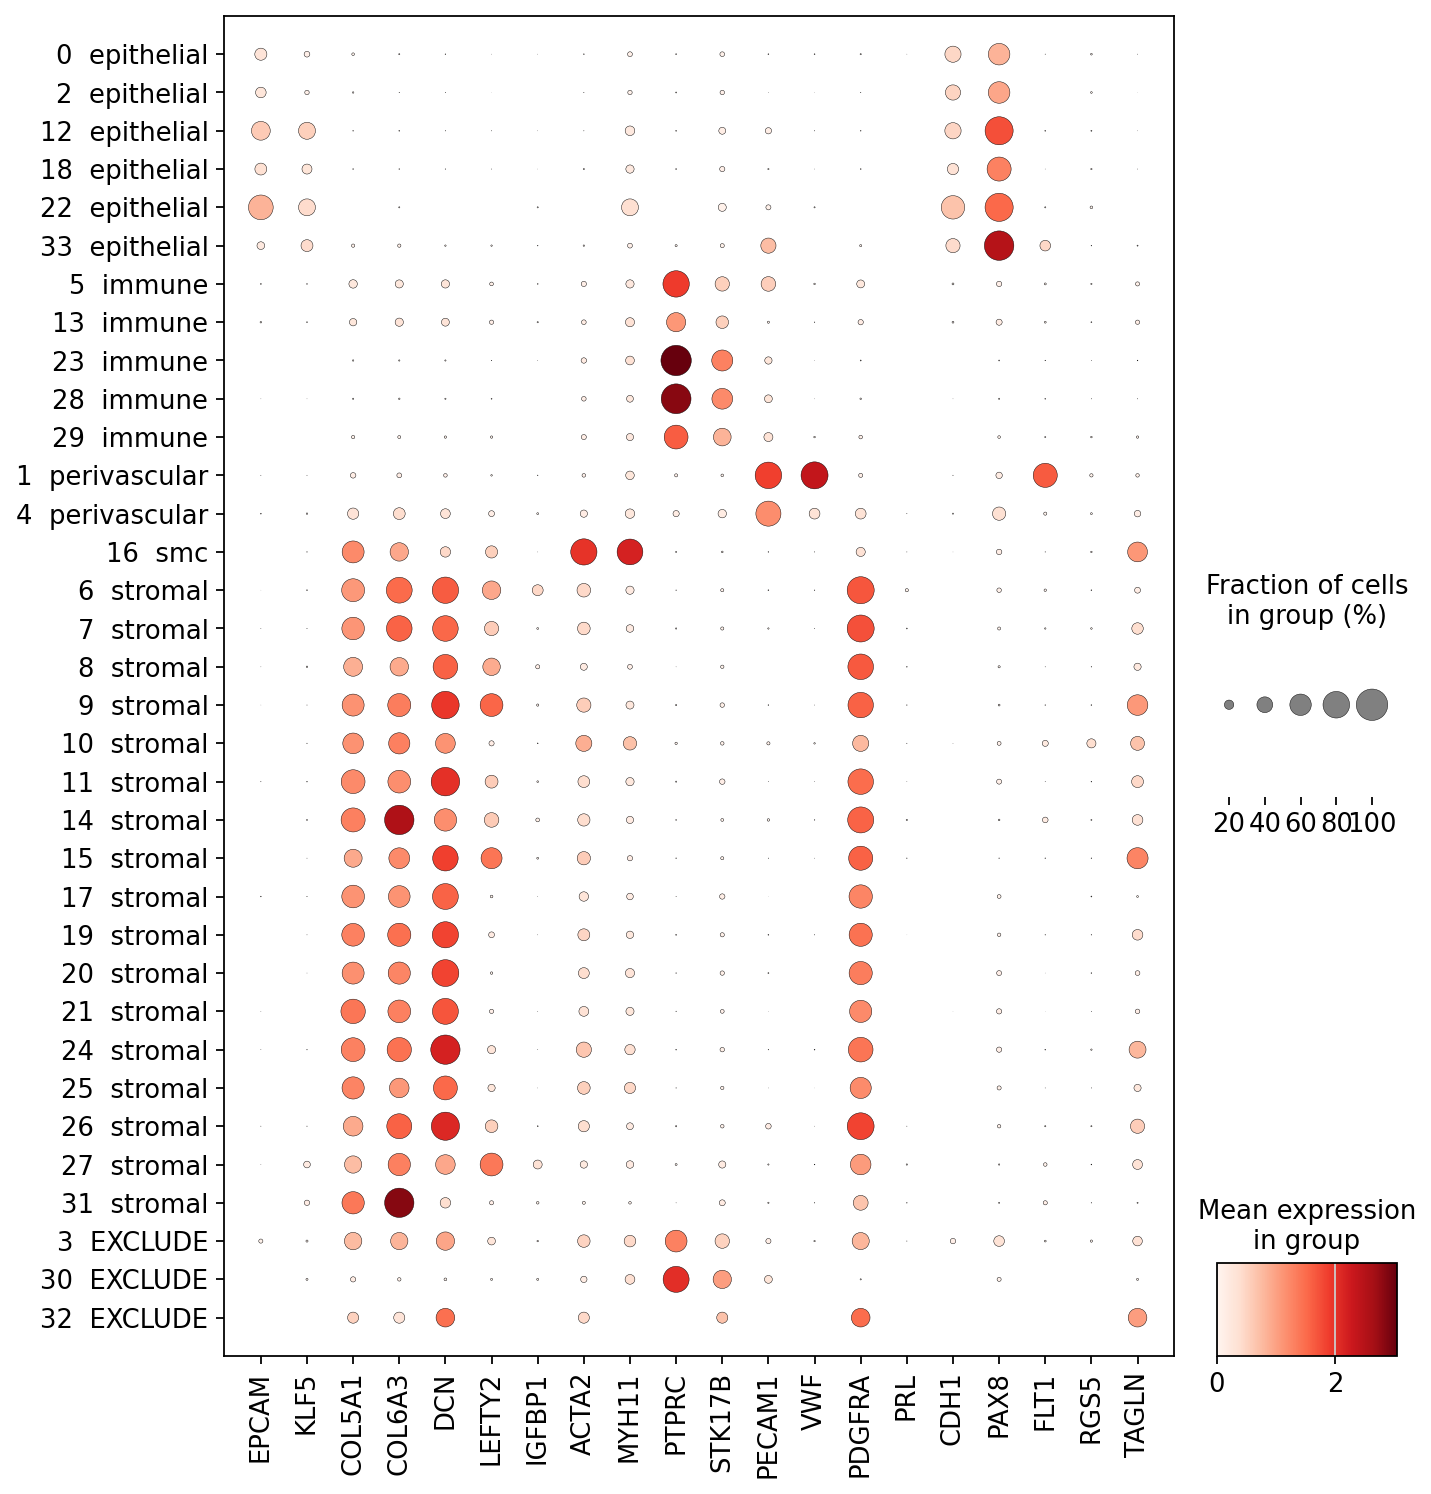

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,1201,epithelial,0.00,2768.0,5434.0
2,4093,epithelial,0.00,2232.0,3938.0
12,4657,epithelial,0.00,2905.0,5648.0
18,1966,epithelial,0.00,2022.0,3458.5
22,80,epithelial,2.12,4901.0,11005.0
33,182,epithelial,0.38,1600.0,3033.0
5,870,immune,0.00,1942.5,3408.5
13,214,immune,0.01,1324.5,2005.0
23,2575,immune,0.00,1255.0,1872.0


## 5. UMAP by cluster and by label

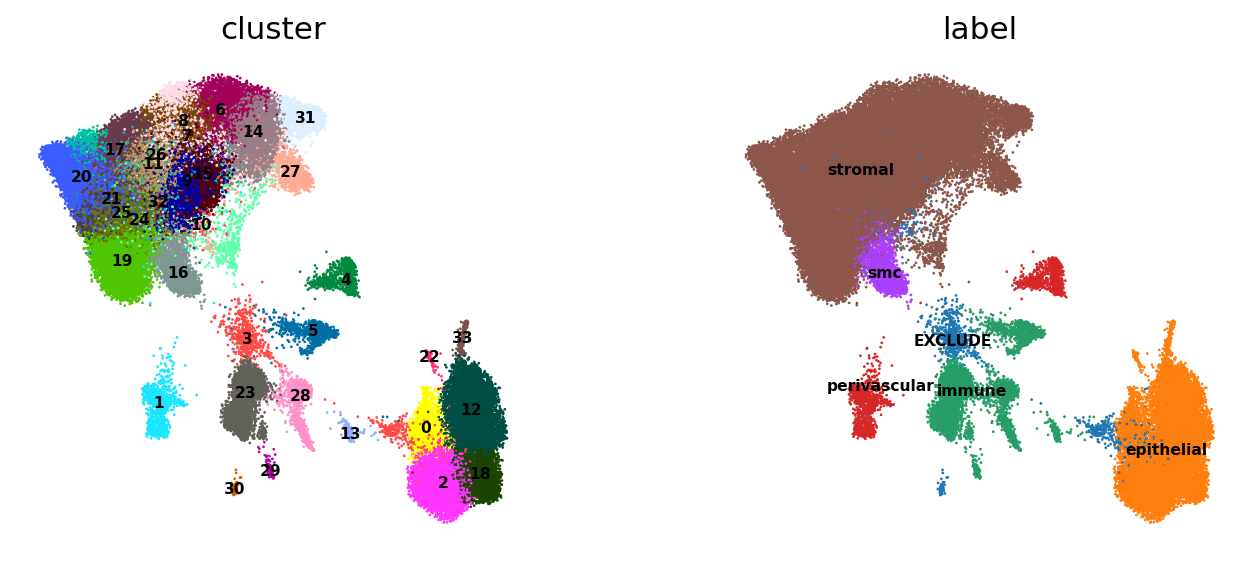

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,EPCAM,KLF5,COL5A1,COL6A3,DCN,LEFTY2,IGFBP1,ACTA2,MYH11,PTPRC,STK17B,PECAM1,VWF,PDGFRA,PRL,CDH1,PAX8,FLT1,RGS5,TAGLN
3,0.07,0.03,0.46,0.45,0.49,0.15,0.02,0.29,0.27,0.61,0.35,0.09,0.02,0.44,0.0,0.10,0.24,0.02,0.03,0.21
30,0.00,0.03,0.09,0.05,0.04,0.03,0.03,0.12,0.21,0.78,0.49,0.16,0.00,0.01,0.0,0.00,0.07,0.00,0.00,0.03
32,0.00,0.00,0.25,0.25,0.50,0.00,0.00,0.25,0.00,0.00,0.25,0.00,0.00,0.50,0.0,0.00,0.00,0.00,0.00,0.50
lineage,0.06,0.05,0.47,0.49,0.54,0.20,0.03,0.22,0.18,0.09,0.11,0.05,0.02,0.50,0.0,0.07,0.18,0.03,0.01,0.18
